# Cookie Cats A/B Test: Exploration and Sanity Checks

**Experiment:** new players were randomly assigned to have the first gate at level 30
(control, `gate_30`) or level 40 (treatment, `gate_40`).
**Goal:** check the experiment is fair before analysing the results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.style.use("default")

df = pd.read_csv("../data/cookie_cats.csv")
df.shape


(90189, 5)

In [2]:
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


In [4]:
print("Duplicate users:", df["userid"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())

Duplicate users: 0
Missing values: 0


In [5]:
df["version"].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [6]:
df["version"].value_counts(normalize=True).round(4)

version
gate_40    0.5044
gate_30    0.4956
Name: proportion, dtype: float64

In [7]:
counts = df["version"].value_counts()
chi2, p_value = stats.chisquare(counts.values)
print(f"Chi-square = {chi2:.2f}, p-value = {p_value:.4f}")

Chi-square = 6.90, p-value = 0.0086


In [8]:
df["sum_gamerounds"].describe().round(1)

count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0
Name: sum_gamerounds, dtype: float64

In [9]:
df.nlargest(3, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


In [10]:
df.groupby("version")["sum_gamerounds"].agg(["count", "mean", "median", "max"]).round(2)

,count,mean,median,max
version,,,,
gate_30,44700,52.46,17.0,49854
gate_40,45489,51.30,16.0,2640


In [11]:
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]
print(df.shape)
df.groupby("version")["sum_gamerounds"].agg(["mean", "median", "max"]).round(2)

(90188, 5)


,mean,median,max
version,,,
gate_30,51.34,17.0,2961
gate_40,51.30,16.0,2640


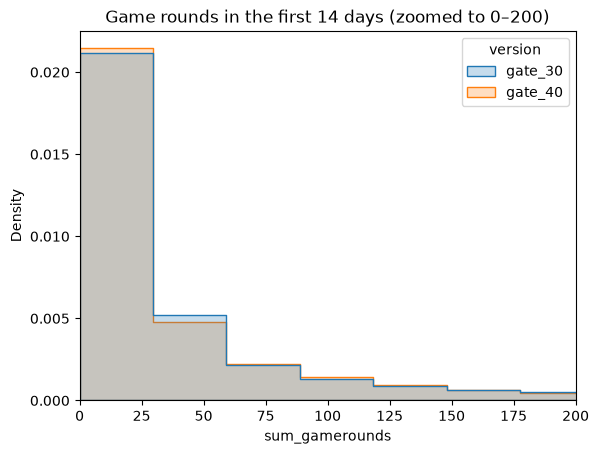

In [12]:
sns.histplot(data=df, x="sum_gamerounds", hue="version", bins=100,
             stat="density", common_norm=False, element="step")
plt.xlim(0, 200)
plt.title("Game rounds in the first 14 days (zoomed to 0–200)")
plt.savefig("../images/gamerounds_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
df.groupby("version")[["retention_1", "retention_7"]].mean().round(4)

,retention_1,retention_7
version,,
gate_30,0.4482,0.1902
gate_40,0.4423,0.1820


## Sanity check findings

- **Data quality:** 90,189 players, no duplicates, no missing values.
- **Sample ratio mismatch:** gate_40 has 45,489 players vs 44,700 for gate_30 (50.4% / 49.6%).
  A chi-square test gives **p = 0.0086**, so the split is very unlikely to be a fair 50/50.
  The imbalance is small, but it's a **limitation**: in a real company I would check the
  assignment process with engineering before trusting the results fully.
- **Outlier removed:** one gate_30 player had **49,854 rounds** in 14 days (next highest: 2,961),
  almost certainly a bot or tracking error. Removing this single row brings the two groups'
  average rounds to 51.34 vs 51.30, nearly identical, as randomization should give.
- **Engagement:** median 16 rounds, mean 51. A few heavy players create a long right tail.
- **First look at retention:** gate_40 is slightly lower on 1-day (44.2% vs 44.8%) and
  7-day retention (18.2% vs 19.0%). Whether these differences are real is tested in Step 2.